In [38]:
import os 
import numpy as np
from PIL import Image
dataset=r"H:\python\fruits-360_100x100\fruits-360"
training=os.path.join(dataset,"training")
print("dataset:",os.path.exists(dataset))
print("dataset:",os.path.exists(training))

dataset: True
dataset: True


In [39]:
classes=os.listdir(training)
print("length of the class:",len(classes))
print("10 class:")
print(classes[:10])

length of the class: 268
10 class:
['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13', 'Apple 14', 'Apple 17', 'Apple 18', 'Apple 19', 'Apple 20']


In [40]:
s_c=[]
for i in ["Apple","Banana","Orange","Mango","Cabbage","Potato"]:
    match=[
    c for c in classes
    if c.lower().startswith(i.lower())]
    if match:
        s_c.append(match[0])
print("s_c:",s_c)
        

s_c: ['Apple 10', 'Banana 1', 'Orange 1', 'Mango 1', 'Cabbage red 1', 'Potato Red 1']


In [41]:
IMG_SIZE=64
MAX_IMAGE=200
x=[]
y=[]
for labels,j in enumerate(s_c):
    class_path=os.path.join(training,j)
    image=os.listdir(class_path)[:MAX_IMAGE]
    print(f"loading {j}:{len(image)} image")
    for k in image:
        image_path=os.path.join(class_path,k)
        try:
             img=Image.open(image_path).convert("RGB")
             img=img.resize((IMG_SIZE,IMG_SIZE))
             x.append(np.array(img))
             y.append(labels)
        except Exception as e:
            print("skipped:",k)
x=np.array(x)
y=np.array(y)
print("image data shape:",x.shape)
print("label shape:",y.shape)

loading Apple 10:200 image
loading Banana 1:200 image
loading Orange 1:200 image
loading Mango 1:200 image
loading Cabbage red 1:149 image
loading Potato Red 1:200 image
image data shape: (1149, 64, 64, 3)
label shape: (1149,)


In [42]:
x=x.astype("float32")/255.0
print("minimum of x:",x.min())
print("maximum of y:",x.max())

minimum of x: 0.0
maximum of y: 1.0


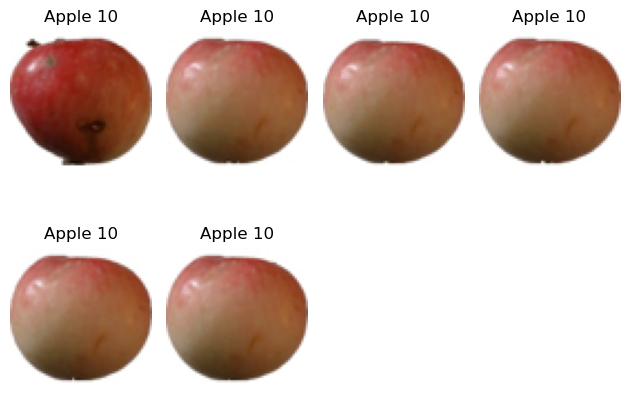

In [43]:
import matplotlib.pyplot as plt
for i in range(6):
    plt.subplot(2,4,i+1)
    plt.imshow(x[i])
    plt.title(s_c[y[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [44]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42,stratify=y)
print("x_train:",x_train.shape[0])
print("x_test:",x_test.shape[0])

x_train: 804
x_test: 345


In [45]:
x_train_flat=x_train.reshape(x_train.shape[0],-1)
x_test_flat=x_test.reshape(x_test.shape[0],-1)
print("training  shape:",x_train_flat.shape)
print("testing shape:",x_test_flat.shape)

training  shape: (804, 12288)
testing shape: (345, 12288)


In [46]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier
model=SVC(kernel="linear",random_state=42,probability=True)
model_1=DecisionTreeClassifier(criterion="gini",random_state=42,max_depth=15)
vote=VotingClassifier(estimators=[("svm",model),("decision_tree",model_1)],
                      voting="soft")
print("Training svm + Decision tree")
vote.fit(x_train_flat,y_train)


Training svm + Decision tree


,estimators,"[('svm', ...), ('decision_tree', ...)]"
,voting,'soft'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0


In [47]:
model.fit(x_train_flat,y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [48]:
model_1.fit(x_train_flat,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


prediction: [3 3 4 1 4 3 2 1 0 3 0 2 3 4 3 3 1 0 2 5 0 3 1 0 4 4 5 0 5 3 0 2 0 3 0 3 3
 3 1 1 1 2 4 2 2 0 5 2 5 2 5 1 3 3 4 0 3 4 5 3 0 1 0 0 3 2 1 4 4 3 3 1 4 1
 0 0 5 1 0 2 5 5 2 1 5 5 5 4 3 0 3 0 5 3 1 1 5 0 4 0 1 4 1 1 0 3 0 5 5 3 2
 2 4 0 2 1 0 3 5 2 1 2 2 4 1 3 5 5 4 0 4 0 3 4 5 4 5 2 5 3 0 1 5 2 4 5 2 1
 3 1 0 4 4 3 3 0 0 3 3 5 1 3 4 3 0 1 4 4 4 1 2 0 2 2 5 3 5 3 2 3 5 4 3 5 5
 3 4 4 4 4 2 0 1 5 3 0 1 0 1 4 0 2 1 3 2 2 2 0 0 0 5 2 4 3 2 5 4 2 0 4 2 1
 2 5 0 4 1 3 1 0 3 0 3 2 0 3 1 5 5 0 1 1 1 0 4 1 5 5 5 5 2 0 2 2 2 1 2 5 2
 3 5 0 0 2 0 3 2 5 1 0 0 4 3 2 0 2 2 3 1 1 0 4 1 4 5 3 1 5 3 5 1 2 3 5 5 4
 1 0 5 2 1 1 2 1 4 5 4 2 1 2 2 1 1 3 3 1 1 5 0 2 5 2 0 5 5 1 3 5 2 0 2 1 3
 1 5 3 5 2 1 0 1 4 2 5 0] 

y_test: [3 3 4 1 4 3 2 1 0 3 0 2 3 4 3 3 1 0 2 5 0 3 1 0 4 4 5 0 5 3 0 2 0 3 0 3 3
 3 1 1 1 2 4 2 2 0 5 2 5 2 5 1 3 3 4 0 3 4 5 3 0 1 0 0 3 2 1 4 4 3 3 1 4 1
 0 0 5 1 0 2 5 5 2 1 5 5 5 4 3 0 3 4 5 3 1 1 5 0 4 0 1 4 1 1 0 3 0 5 5 3 2
 2 4 0 2 1 0 3 5 2 1 2 2 4 1 3 5 5 4 0 4 0 3 4 5 4 5

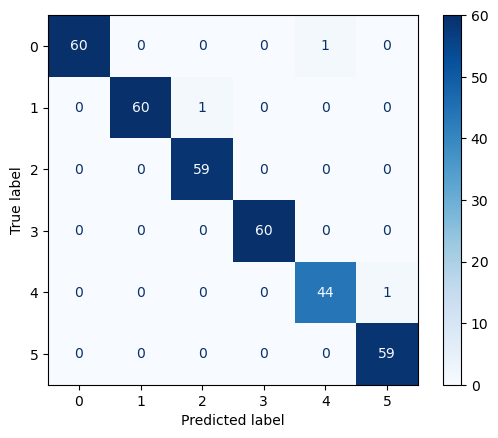

In [49]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,ConfusionMatrixDisplay
pred=vote.predict(x_test_flat)
print("prediction:",pred,"\n")
print("y_test:",y_test,"\n")
accu=accuracy_score(pred,y_test)
print("accurasy score:",accu,"\n")
confusion=confusion_matrix(pred,y_test)
print("confusion_matrix:\n",confusion,"\n")
display=ConfusionMatrixDisplay((confusion),display_labels=vote.classes_)
print(display)
display.plot(cmap="Blues",values_format='d')

In [50]:
svm_pred=model.predict(x_test_flat)
print("svm prediction:",svm_pred)
svm_accu=accuracy_score(svm_pred,y_test)
print("accurasy score:",svm_accu,"\n")
con=confusion_matrix(svm_pred,y_test)
print("confusion_matrix:\n",con,"\n")

svm prediction: [3 3 4 1 4 3 2 1 0 3 0 2 3 4 3 3 1 0 2 5 0 3 1 0 4 4 5 0 5 3 0 2 0 3 0 3 3
 3 1 1 1 2 4 2 2 0 5 2 5 2 5 1 3 3 4 0 3 4 5 3 0 1 0 0 3 2 1 4 4 3 3 1 4 1
 0 0 5 1 0 2 5 5 2 1 5 5 5 4 3 0 3 4 5 3 1 1 5 0 4 0 1 4 1 1 0 3 0 5 5 3 2
 2 4 0 2 1 0 3 5 2 1 2 2 4 1 3 5 5 4 0 4 0 3 4 5 4 5 2 5 3 0 1 5 2 4 5 2 1
 3 1 0 4 4 3 3 0 0 3 3 5 1 3 4 3 0 1 4 4 4 1 2 0 2 2 5 3 5 3 2 3 5 4 3 5 5
 3 4 5 4 4 2 0 1 5 3 0 1 0 1 4 0 2 1 3 2 2 2 0 0 0 5 2 4 3 2 5 4 2 0 4 2 1
 2 5 0 4 1 3 1 0 3 0 3 2 0 3 1 5 5 0 1 1 1 0 4 1 5 5 5 5 2 0 2 2 2 1 2 5 2
 3 5 0 0 2 0 3 2 5 1 0 0 4 3 2 0 2 2 3 1 1 0 4 1 4 5 3 1 5 3 5 1 2 3 5 5 4
 1 0 5 2 1 1 2 1 4 5 4 2 1 2 2 1 1 3 3 1 1 5 0 2 5 2 0 5 5 1 3 5 2 0 2 1 3
 1 5 3 5 2 1 0 2 4 2 5 0]
accurasy score: 1.0 

confusion_matrix:
 [[60  0  0  0  0  0]
 [ 0 60  0  0  0  0]
 [ 0  0 60  0  0  0]
 [ 0  0  0 60  0  0]
 [ 0  0  0  0 45  0]
 [ 0  0  0  0  0 60]] 



In [51]:
tree_pred=model.predict(x_test_flat)
print("tree prediction:",tree_pred)
tree_accu=accuracy_score(tree_pred,y_test)
print("accurasy score:",tree_accu,"\n")
con_tree=confusion_matrix(tree_pred,y_test)
print("confusion_matrix:\n",con_tree,"\n")

tree prediction: [3 3 4 1 4 3 2 1 0 3 0 2 3 4 3 3 1 0 2 5 0 3 1 0 4 4 5 0 5 3 0 2 0 3 0 3 3
 3 1 1 1 2 4 2 2 0 5 2 5 2 5 1 3 3 4 0 3 4 5 3 0 1 0 0 3 2 1 4 4 3 3 1 4 1
 0 0 5 1 0 2 5 5 2 1 5 5 5 4 3 0 3 4 5 3 1 1 5 0 4 0 1 4 1 1 0 3 0 5 5 3 2
 2 4 0 2 1 0 3 5 2 1 2 2 4 1 3 5 5 4 0 4 0 3 4 5 4 5 2 5 3 0 1 5 2 4 5 2 1
 3 1 0 4 4 3 3 0 0 3 3 5 1 3 4 3 0 1 4 4 4 1 2 0 2 2 5 3 5 3 2 3 5 4 3 5 5
 3 4 5 4 4 2 0 1 5 3 0 1 0 1 4 0 2 1 3 2 2 2 0 0 0 5 2 4 3 2 5 4 2 0 4 2 1
 2 5 0 4 1 3 1 0 3 0 3 2 0 3 1 5 5 0 1 1 1 0 4 1 5 5 5 5 2 0 2 2 2 1 2 5 2
 3 5 0 0 2 0 3 2 5 1 0 0 4 3 2 0 2 2 3 1 1 0 4 1 4 5 3 1 5 3 5 1 2 3 5 5 4
 1 0 5 2 1 1 2 1 4 5 4 2 1 2 2 1 1 3 3 1 1 5 0 2 5 2 0 5 5 1 3 5 2 0 2 1 3
 1 5 3 5 2 1 0 2 4 2 5 0]
accurasy score: 1.0 

confusion_matrix:
 [[60  0  0  0  0  0]
 [ 0 60  0  0  0  0]
 [ 0  0 60  0  0  0]
 [ 0  0  0 60  0  0]
 [ 0  0  0  0 45  0]
 [ 0  0  0  0  0 60]] 



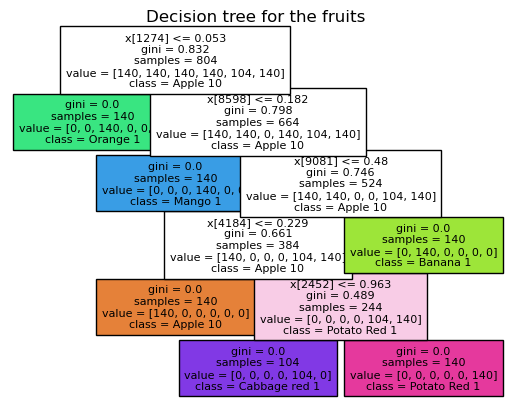

In [52]:
from sklearn.tree import plot_tree
plot_tree(model_1,filled=True,feature_names=None,class_names=s_c,max_depth=7,fontsize=8)
plt.title("Decision tree for the fruits ")
plt.show()

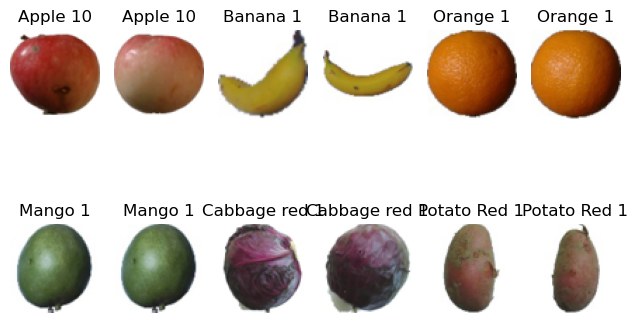

In [53]:
apple=np.where(y==s_c.index("Apple 10"))[0][:2]
banana=np.where(y==s_c.index("Banana 1"))[0][:2]
orange=np.where(y==s_c.index("Orange 1"))[0][:2]
mango=np.where(y==s_c.index("Mango 1"))[0][:2]
cabbage=np.where(y==s_c.index("Cabbage red 1"))[0][:2]
potato=np.where(y==s_c.index("Potato Red 1"))[0][:2]
index=np.concatenate([apple,banana,orange,mango,cabbage,potato])
for i ,idx in enumerate(index):
    plt.subplot(2,6,i+1)
    plt.imshow(x[idx])
    plt.title(s_c[y[idx]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [54]:
print(s_c)

['Apple 10', 'Banana 1', 'Orange 1', 'Mango 1', 'Cabbage red 1', 'Potato Red 1']


Input Image: H:\python\fruits-360_100x100\fruits-360\Test\Cabbage red 1\r1_3_100.jpg
Predicted Fruit: Cabbage red 1
Confidence: 98.14 %


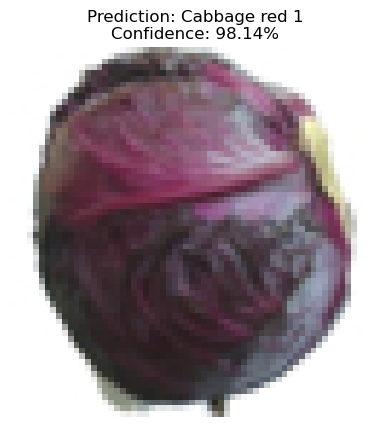

In [58]:
image_path = r"H:\python\fruits-360_100x100\fruits-360\Test\Cabbage red 1\r1_3_100.jpg"

print("Input Image:", image_path)
print("Predicted Fruit:", predicted_fruit)
print("Confidence:", round(confidence, 2), "%")
plt.imshow(img)
plt.title(
        f"Prediction: {predicted_fruit}\n"
        f"Confidence: {confidence:.2f}%"    )
plt.axis("off")
plt.show()
